### Projeto de teste
O objetivo desse pequeno projeto é aplicar as habilidades da disciplina em dados externos.
O banco de dados em questão é o 'Dicionário de Dados - Docentes' que foram obtidos na 'https://dados.ufrn.br/dataset/docentes'

Perguntas norteadoras:
- Em quais lotações temos mais professores?
- Qual a distribuição de professores homens e mulheres em locações da área de STEM?
- Temos mais homens ou mulheres com formação de doutorado e mestrado?


01 - Configurando o versionamento GIT

In [117]:
import sys

print(f"Versão do Python: {sys.version}")
print(f"Executável em uso: {sys.executable}")


Versão do Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Executável em uso: c:\Users\USER\AppData\Local\Programs\Python\Python312\python.exe


In [118]:
%cd "C:/Users/USER/Documents/Projetos/Estudos/Ciencia de dados/Unidade_01/Professores_ufrn"
%pwd
!git init
!git config user.name "hannavit42"
!git config user.email "hannavitoria2027a@gmail.com"
!git status

C:\Users\USER\Documents\Projetos\Estudos\Ciencia de dados\Unidade_01\Professores_ufrn
Reinitialized existing Git repository in C:/Users/USER/Documents/Projetos/Estudos/Ciencia de dados/Unidade_01/Professores_ufrn/.git/
On branch master
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	notebooks/
	reports/
	requirements.txt

nothing added to commit but untracked files present (use "git add" to track)


In [119]:
!git status
!git config --list --local


On branch master
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	notebooks/
	reports/
	requirements.txt

nothing added to commit but untracked files present (use "git add" to track)
core.repositoryformatversion=0
core.filemode=false
core.bare=false
core.logallrefupdates=true
core.symlinks=false
core.ignorecase=true
user.name=hannavit42
user.email=hannavitoria2027a@gmail.com


In [120]:
!git add README.md
!git commit -m "Adicionado o arquivo README.md"
!git log --oneline

On branch master
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	notebooks/
	reports/
	requirements.txt

nothing added to commit but untracked files present (use "git add" to track)
cdc1f28 Adicionado o arquivo README.md


In [121]:
%%writefile .gitignore
.venv/
__pycache__/
*.env
.ipynb_checkpoints/
# O .gitignore faz parte do projeto e deve ser versionado
!git add .gitignore
!git commit -m "Adiciona .gitignore para ambiente, dados e segredos"
!git log --oneline

Overwriting .gitignore


Importando os dados

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# acrescenta data/ no .gitignore so se ainda nao estiver la
gitignore = Path(".gitignore")
texto = gitignore.read_text()
if "data/" not in texto:
    gitignore.write_text(texto + "data/\n")

!type .gitignore

In [123]:
pasta_dados = Path("C:/Users/USER/Documents/Projetos/Estudos/Ciencia de dados/Unidade_01/Professores_ufrn/data")
pasta_dados.mkdir(exist_ok=True)
caminho = pasta_dados / "docentes.csv"
prof = pd.read_csv(caminho, sep=";")



In [124]:
prof.head(3) # Visualização do cabeçalho; Aqui percebemos que as colunas já estão normalizadas
prof.tail()



,siape,nome,sexo,formacao,tipo_jornada_trabalho,vinculo,categoria,classe_funcional,id_unidade_lotacao,lotacao,admissao
2860,3492317,SHANTANU GUPTA,M,DOUTORADO,Dedicação exclusiva,Professor Visitante,PROFESSOR MAGISTERIO SUPERIOR - VISITANTE,Classe C - Associado ...,6069,INSTITUTO METROPOLE DIGITAL,2025/08/06 00:00:00.000000000
2861,434879,SILVANIA SOUSA DO NASCIMENTO,F,DOUTORADO,Dedicação exclusiva,Professor Visitante,PROFESSOR MAGISTERIO SUPERIOR - VISITANTE,Classe D - Titular ...,6025,INSTITUTO DE QUÍMICA,2025/08/01 00:00:00.000000000
2862,3535011,SUYLAN LOURDES DE ARAUJO DANTAS,F,DOUTORADO,Dedicação exclusiva,Professor Visitante,PROFESSOR MAGISTERIO SUPERIOR - VISITANTE,Classe B - Adjunto ...,57,DEPARTAMENTO DE ENGENHARIA QUIMICA,2026/05/26 00:00:00.000000000
2863,3490605,TELTON PEDRO ANSELMO RAMOS,M,DOUTORADO,Dedicação exclusiva,Professor Visitante,PROFESSOR MAGISTERIO SUPERIOR - VISITANTE,Classe D - Titular ...,183,DEPARTAMENTO DE BOTÂNICA E ZOOLOGIA,2025/08/01 00:00:00.000000000
2864,3330361,VASILIKI LAGOU,F,DOUTORADO,Dedicação exclusiva,Professor Visitante,PROFESSOR MAGISTERIO SUPERIOR - VISITANTE,Classe D - Titular ...,6069,INSTITUTO METROPOLE DIGITAL,2023/02/15 00:00:00.000000000


In [125]:
prof.shape # Visualização do tamanho do DataFrame; Aqui percebemos que temos 2865 linhas e 11 colunas

(2865, 11)

In [126]:
prof.info() 


<class 'pandas.DataFrame'>
RangeIndex: 2865 entries, 0 to 2864
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   siape                  2865 non-null   int64
 1   nome                   2865 non-null   str  
 2   sexo                   2865 non-null   str  
 3   formacao               2865 non-null   str  
 4   tipo_jornada_trabalho  2865 non-null   str  
 5   vinculo                2865 non-null   str  
 6   categoria              2865 non-null   str  
 7   classe_funcional       2865 non-null   str  
 8   id_unidade_lotacao     2865 non-null   int64
 9   lotacao                2865 non-null   str  
 10  admissao               2865 non-null   str  
dtypes: int64(2), str(9)
memory usage: 246.3 KB


In [127]:
prof.isna().sum().sort_values(ascending=False)


siape                    0
nome                     0
sexo                     0
formacao                 0
tipo_jornada_trabalho    0
vinculo                  0
categoria                0
classe_funcional         0
id_unidade_lotacao       0
lotacao                  0
admissao                 0
dtype: int64

In [128]:
prof.duplicated().sum() # Visualização de valores duplicados; Aqui não teomos valores duplicados, ou seja, cada linha é única e não há registros repetidos no DataFrame.


np.int64(0)

Não temos colunas ausentes, todas as 2865 linhas estão preenchidas em todas as colunas, portanto não precisaremos fazer a limpeza dos dados.
Mas dale reparar que a coluna 'admissao' é uma data

In [129]:
# convertendo a coluna "admissao" para o tipo datetime
prof["admissao"] = pd.to_datetime(prof["admissao"])
prof["admissao"].dtype

dtype('<M8[ns]')

In [130]:
prof.info()
prof.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 2865 entries, 0 to 2864
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   siape                  2865 non-null   int64         
 1   nome                   2865 non-null   str           
 2   sexo                   2865 non-null   str           
 3   formacao               2865 non-null   str           
 4   tipo_jornada_trabalho  2865 non-null   str           
 5   vinculo                2865 non-null   str           
 6   categoria              2865 non-null   str           
 7   classe_funcional       2865 non-null   str           
 8   id_unidade_lotacao     2865 non-null   int64         
 9   lotacao                2865 non-null   str           
 10  admissao               2865 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(2), str(8)
memory usage: 246.3 KB


,siape,nome,sexo,formacao,tipo_jornada_trabalho,vinculo,categoria,classe_funcional,id_unidade_lotacao,lotacao,admissao
0,1543339,ADELE GUIMARAES UBARANA SANTOS,F,MESTRADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Classe C ...,1452,NÚCLEO DE EDUCAÇÃO DA INFÂNCIA,2006-07-24
1,1554468,AFRANIO CESAR DE ARAUJO,M,DOUTORADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Titular ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2008-09-12
2,1177821,AIRTON FERNANDES GUIMARAES FILHO,M,MESTRADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Classe C ...,284,ESCOLA DE MÚSICA,1998-04-28
3,2360824,ALDAIR RODRIGUES DA SILVA,M,MESTRADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Classe B ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2017-01-25
4,2364334,ALESSANDRA MENDES PACHECO,F,DOUTORADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Titular ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2009-10-13


In [131]:
data_referencia = pd.Timestamp("2026-10-14")

prof["anos_trabalho"] = (
    data_referencia.year
    - prof["admissao"].dt.year
    - (
        (prof["admissao"].dt.month > data_referencia.month)
        | (
            (prof["admissao"].dt.month == data_referencia.month)
            & (prof["admissao"].dt.day > data_referencia.day)
        )
    ).astype(int)
)
prof.head(2)

,siape,nome,sexo,formacao,tipo_jornada_trabalho,vinculo,categoria,classe_funcional,id_unidade_lotacao,lotacao,admissao,anos_trabalho
0,1543339,ADELE GUIMARAES UBARANA SANTOS,F,MESTRADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Classe C ...,1452,NÚCLEO DE EDUCAÇÃO DA INFÂNCIA,2006-07-24,20
1,1554468,AFRANIO CESAR DE ARAUJO,M,DOUTORADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Titular ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2008-09-12,18


## Avaliação inicial dos dados

In [132]:
print(f"Total de lotações distintas: {prof['lotacao'].nunique()}")

print('Número de professores por lotação')
prof["lotacao"].value_counts()

Total de lotações distintas: 131
Número de professores por lotação


lotacao
ESCOLA AGRÍCOLA DE JUNDIAÍ                                         119
FACULDADE DE CIÊNCIAS DA SAÚDE DO TRAIRI - FACISA                  116
ESCOLA DE CIÊNCIAS E TECNOLOGIA                                    107
ESCOLA MULTICAMPI DE CIÊNCIAS MÉDICAS DO RIO GRANDE DO NORTE        81
INSTITUTO METROPOLE DIGITAL                                         75
                                                                  ... 
PROGRAMA DE PÓS-GRADUAÇÃO EM GESTÃO DE PROCESSOS INSTITUCIONAIS      1
SUPERINTENDENCIA DE COMUNICACAO                                      1
SECRETARIA DE GOVERNANÇA INSTITUCIONAL                               1
NÚCLEO DE ARTE E CULTURA                                             1
SUPERINTENDÊNCIA DO HUOL - EBSERH                                    1
Name: count, Length: 131, dtype: int64

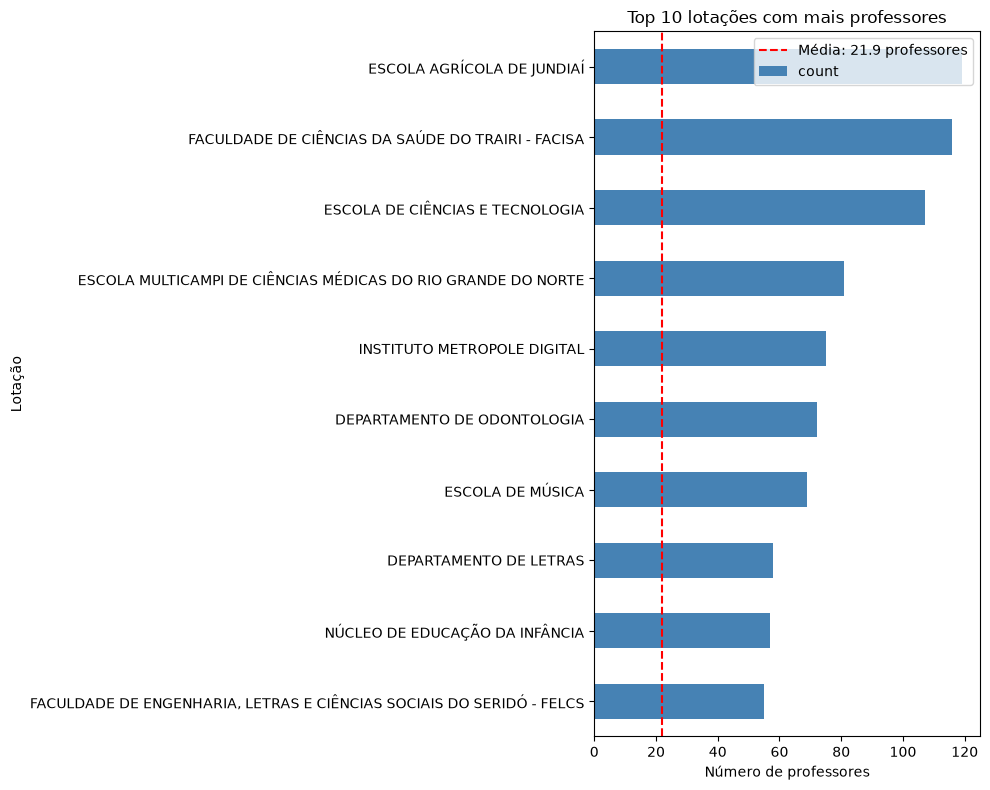

In [140]:

contagem_lotacoes = prof["lotacao"].value_counts()
media_por_lotacao = contagem_lotacoes.mean()
top_10 = contagem_lotacoes.head(10).sort_values()

ax = top_10.plot(kind="barh", figsize=(10, 8), color="steelblue")
ax.axvline(
    media_por_lotacao,
    color="red",
    linestyle="--",
    label=f"Média: {media_por_lotacao:.1f} professores"
)

ax.set_title("Top 10 lotações com mais professores")
ax.set_xlabel("Número de professores")
ax.set_ylabel("Lotação")
ax.legend()
plt.tight_layout()
plt.show()

In [134]:
EAJ = prof[prof["lotacao"] == "ESCOLA AGRÍCOLA DE JUNDIAÍ"]
EAJ.head(5)

,siape,nome,sexo,formacao,tipo_jornada_trabalho,vinculo,categoria,classe_funcional,id_unidade_lotacao,lotacao,admissao,anos_trabalho
1,1554468,AFRANIO CESAR DE ARAUJO,M,DOUTORADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Titular ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2008-09-12,18
3,2360824,ALDAIR RODRIGUES DA SILVA,M,MESTRADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Classe B ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2017-01-25,9
4,2364334,ALESSANDRA MENDES PACHECO,F,DOUTORADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Titular ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2009-10-13,17
12,3245745,AMANDA VIVIANI VOGAS,F,MESTRADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Classe B ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2021-07-02,5
17,1747540,ANA PAULA COSTA CAMARA,F,DOUTORADO,Dedicação exclusiva,Ativo Permanente,PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO,Titular ...,351,ESCOLA AGRÍCOLA DE JUNDIAÍ,2015-07-03,11


Aqui observamos que a Escola Agrícola de Jundiai tem bastante docentes de ensino básico, técnico e tecnológico. Como queremos restringir essas análises apenas para o nível superior, realizaremos filtros

In [135]:
print(f"Total de lotações distintas: {prof['categoria'].nunique()}")

print('Número de professores por categoria')
prof["categoria"].value_counts()

Total de lotações distintas: 7
Número de professores por categoria


categoria
PROFESSOR DO MAGISTERIO SUPERIOR                    2208
PROFESSOR DO MAGISTERIO SUPERIOR - SUBSTITUTO        278
PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO     211
PROFESSOR DO MAGISTERIO SUPERIOR - TEMPORARIO         64
PROFESSOR MAGISTERIO SUPERIOR - VISITANTE             64
PROF ENS BAS TEC TECNOLOGICO-SUBSTITUTO               37
PROFESSOR TIT-LIVRE MAGIST SUPERIOR                    3
Name: count, dtype: int64

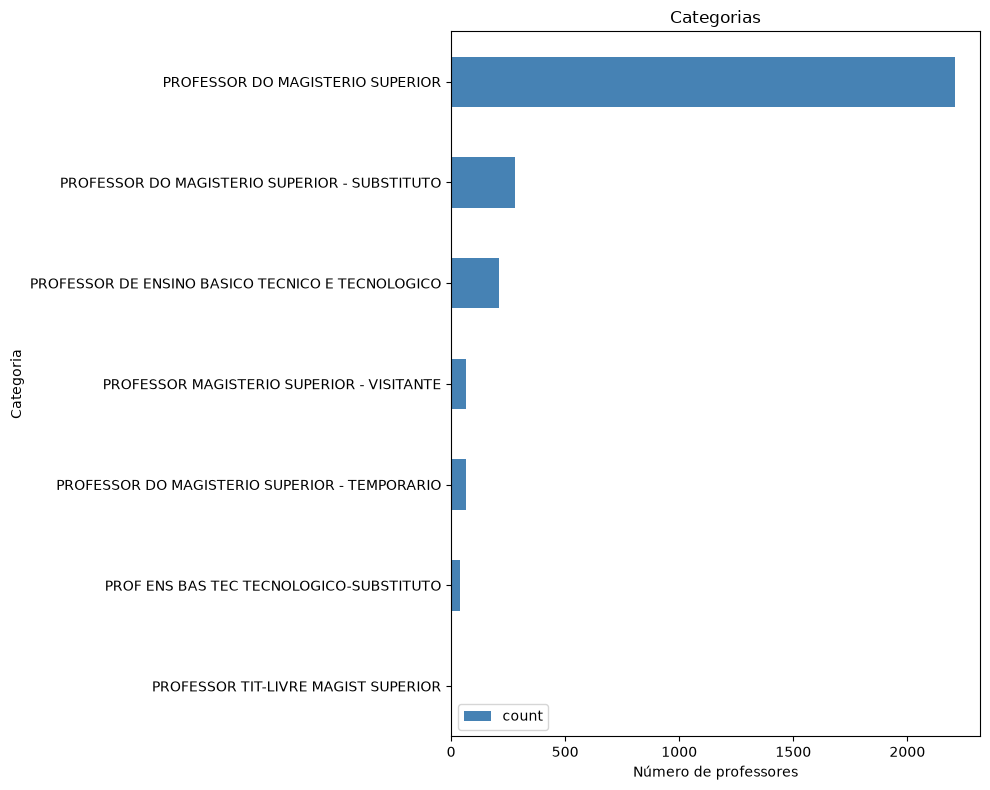

In [136]:


contagem_categorias = prof["categoria"].value_counts()
top_20 = contagem_categorias.head(20).sort_values()

ax = top_20.plot(kind="barh", figsize=(10, 8), color="steelblue")


ax.set_title("Categorias")
ax.set_xlabel("Número de professores")
ax.set_ylabel("Categoria")
ax.legend()
plt.tight_layout()
plt.show()

In [137]:
mapa_categoria = {
    "PROFESSOR DO MAGISTERIO SUPERIOR": "Superior",
    "PROFESSOR DO MAGISTERIO SUPERIOR - SUBSTITUTO": "Superior",
    "PROFESSOR DO MAGISTERIO SUPERIOR - TEMPORARIO": "Superior",
    "PROFESSOR MAGISTERIO SUPERIOR - VISITANTE": "Superior",
    "PROFESSOR TIT-LIVRE MAGIST SUPERIOR": "Superior",
    "PROFESSOR DE ENSINO BASICO TECNICO E TECNOLOGICO": "Tecnico",
    "PROF ENS BAS TEC TECNOLOGICO-SUBSTITUTO": "Tecnico",
}

prof["categoria_resumida"] = prof["categoria"].map(mapa_categoria)

prof["categoria_resumida"].value_counts()


categoria_resumida
Superior    2617
Tecnico      248
Name: count, dtype: int64

## Visualizando locações com mais e menos professores por categoria

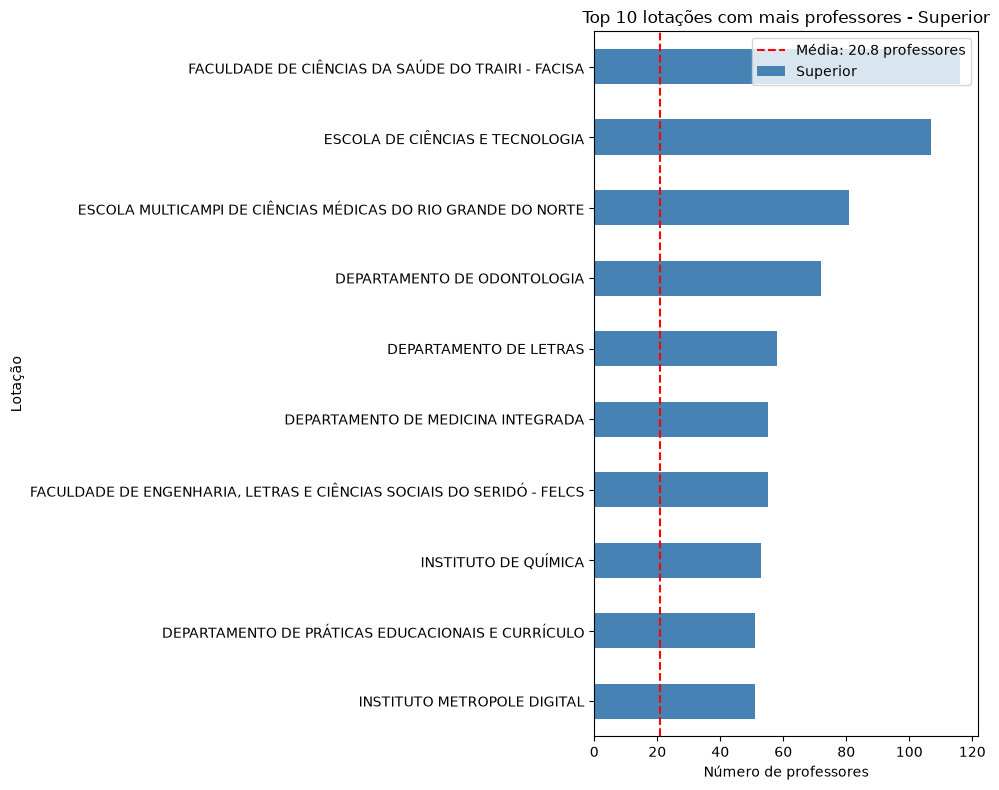

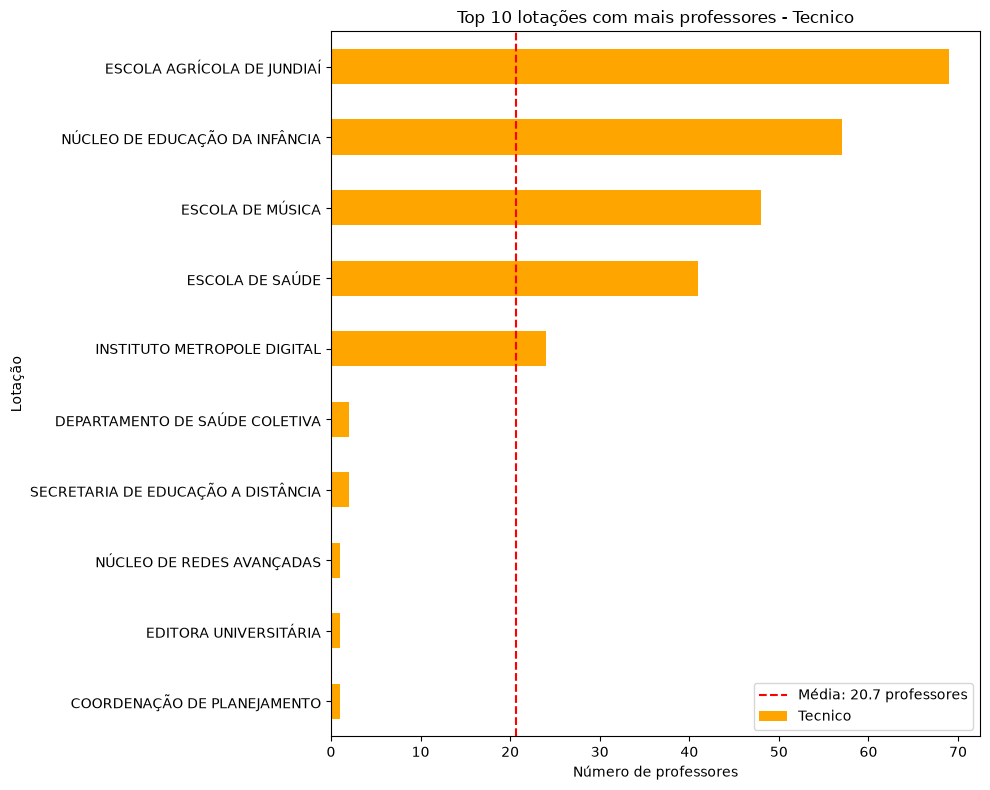

In [141]:

contagem = prof.groupby(["lotacao", "categoria_resumida"]).size().unstack(fill_value=0)

for categoria, cor in [("Superior", "steelblue"), ("Tecnico", "orange")]:
    serie = contagem[categoria]
    serie = serie[serie > 0]
    media = serie.mean()
    top_10 = serie.sort_values(ascending=False).head(10).sort_values()

    ax = top_10.plot(kind="barh", figsize=(10, 8), color=cor)
    ax.axvline(
        media,
        color="red",
        linestyle="--",
        label=f"Média: {media:.1f} professores"
    )

    ax.set_title(f"Top 10 lotações com mais professores - {categoria}")
    ax.set_xlabel("Número de professores")
    ax.set_ylabel("Lotação")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
ax = prof["anos_trabalho"].plot(
    kind="hist",
    bins=20,
    figsize=(10, 6),
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Distribuição de professores por anos de trabalho")
ax.set_xlabel("Anos de trabalho")
ax.set_ylabel("Número de professores")
plt.tight_layout()
plt.show()

## Cruzando sexo, formação e classe funcional

Antes dos gráficos, a limpeza: algumas colunas de texto vêm com espaços sobrando no final e a `classe_funcional` aparece escrita de dois jeitos ("Classe C" e "Classe C - Associado").

In [ ]:
colunas_texto = ["lotacao", "formacao", "tipo_jornada_trabalho", "vinculo", "classe_funcional"]
for col in colunas_texto:
    prof[col] = prof[col].str.strip()

# unifica as classes escritas de dois jeitos e agrupa as sem informacao
prof["classe_funcional"] = prof["classe_funcional"].replace({
    "Classe A": "Classe A - Assistente",
    "Classe B": "Classe B - Adjunto",
    "Classe C": "Classe C - Associado",
    "Classe D": "Classe D - Titular",
    "Titular": "Classe D - Titular",
    "U": "Não informada",
    "Não Informada": "Não informada",
})

# daqui para frente so o magisterio superior
superior = prof[prof["categoria_resumida"] == "Superior"].copy()
superior["classe_funcional"].value_counts()

### Sexo por lotação da área de STEM

Não existe uma coluna de área, então a seleção é feita por palavras no nome da lotação (engenharias, matemática, física, computação, estatística, química, geologia e afins). Lotações mistas, como a FELCS, ficaram de fora.

In [ ]:
# tira os acentos so para facilitar a busca pelo nome
nome_sem_acento = (
    superior["lotacao"]
    .str.normalize("NFKD")
    .str.encode("ascii", "ignore")
    .str.decode("ascii")
)

palavras_stem = (
    "ENGENHARIA|MATEMATICA|FISICA TEORICA|INTERNACIONAL DE FISICA|INFORMATICA|COMPUTACAO"
    "|ESTATISTICA|INSTITUTO DE QUIMICA|GEOLOGIA|GEOFISICA|METROPOLE DIGITAL|CIENCIAS EXATAS"
    "|ESCOLA DE CIENCIAS E TECNOLOGIA|CIENCIAS ATMOSFERICAS"
)
eh_stem = nome_sem_acento.str.contains(palavras_stem) & ~nome_sem_acento.str.contains("FELCS")
stem = superior[eh_stem]

print(f"Lotações STEM: {stem['lotacao'].nunique()} | docentes: {len(stem)}")
stem["sexo"].value_counts()

In [ ]:
tabela_sexo = stem.groupby(["lotacao", "sexo"]).size().unstack(fill_value=0)
tabela_sexo = tabela_sexo[tabela_sexo.sum(axis=1) >= 10]  # ignora lotacoes muito pequenas

# percentual de cada sexo dentro da lotacao
pct_sexo = tabela_sexo.div(tabela_sexo.sum(axis=1), axis=0) * 100
pct_sexo = pct_sexo.sort_values("F")
pct_sexo.index = pct_sexo.index.str.replace("DEPARTAMENTO DE ", "", regex=False)

ax = pct_sexo[["F", "M"]].rename(columns={"F": "Feminino", "M": "Masculino"}).plot(
    kind="barh", figsize=(10, 14), width=0.8, color=["#d1495b", "steelblue"]
)
ax.axvline(50, color="black", linestyle="--")
ax.set_title("Proporção de docentes por sexo nas lotações de STEM")
ax.set_xlabel("% dos docentes")
ax.set_ylabel("Lotação")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))  # legenda fora do grafico
plt.tight_layout()
plt.show()

### Formação por sexo

In [ ]:
formacao_sexo = pd.crosstab(superior["formacao"], superior["sexo"])
ordem = ["DOUTORADO", "MESTRADO", "ESPECIALIZAÇÃO", "GRADUAÇÃO"]
formacao_sexo = formacao_sexo.reindex([f for f in ordem if f in formacao_sexo.index])

ax = formacao_sexo.plot(kind="bar", figsize=(9, 6), color=["#d1495b", "steelblue"], rot=0)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("Formação dos docentes do magistério superior, por sexo")
ax.set_xlabel("Formação")
ax.set_ylabel("Número de docentes")
ax.legend(["Feminino", "Masculino"])
plt.tight_layout()
plt.show()

# proporcao de mulheres em cada nivel de formacao
(formacao_sexo["F"] / formacao_sexo.sum(axis=1) * 100).round(1)

### Sexo por classe funcional

Se a proporção de mulheres cai nas classes mais altas da carreira, o gráfico mostra.

In [ ]:
ordem_classes = [
    "Classe A - Assistente",
    "Classe B - Adjunto",
    "Classe C - Associado",
    "Classe D - Titular",
]
classe_sexo = pd.crosstab(superior["classe_funcional"], superior["sexo"], normalize="index") * 100
classe_sexo = classe_sexo.reindex(ordem_classes)

ax = classe_sexo[["F", "M"]].rename(columns={"F": "Feminino", "M": "Masculino"}).plot(
    kind="barh", figsize=(10, 6), width=0.8, color=["#d1495b", "steelblue"]
)
ax.axvline(50, color="black", linestyle="--")
ax.invert_yaxis()  # classe A em cima, titular embaixo
ax.set_title("Proporção de docentes por sexo em cada classe funcional")
ax.set_xlabel("% dos docentes")
ax.set_ylabel("Classe funcional")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))  # legenda fora do grafico
plt.tight_layout()
plt.show()

classe_sexo.round(1)